# Лабораторная работа №6 — высокопроизводительная обработка данных NumPy

**Вариант 8: GPS-телеметрия транспорта**  
Студент: Шубин В. Ю., группа ИВТб-1303-06-00

Исходный файл: `data_variant_8.csv` (2 000 000 записей, seed 20080826).  
Поля: `ts`, `vehicle_id`, `speed`, `fuel`, `engine`, `acc`.

В работе запрещены циклы по строкам исходного массива. Используются булевы маски, `np.where`, `np.clip`, `np.unique`, кумулятивные суммы и цикл только по группам.


In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

DATA_PATH = Path("data_variant_8.csv")
DTYPE = np.dtype([
    ("ts", np.int32),
    ("vehicle_id", np.int16),
    ("speed", np.float32),
    ("fuel", np.float32),
    ("engine", np.float32),
    ("acc", np.uint8),
])

print("Файл:", DATA_PATH.resolve())
print("Размер файла:", f"{DATA_PATH.stat().st_size / 1024**2:.1f} МиБ")


Файл: C:\Users\shubi\Desktop\labs\1 курс\proga\progalab 6\data_variant_8.csv
Размер файла: 90.3 МиБ


## 1. Загрузка и подготовка типов

Читаем CSV в структурированный массив с заданным `dtype`, оцениваем объём памяти и долю некорректных значений `NaN`/`Inf`.


In [2]:
data = np.genfromtxt(
    DATA_PATH,
    delimiter=",",
    skip_header=1,
    dtype=DTYPE,
    encoding="utf-8",
)

n_raw = data.size
raw_nbytes = data.nbytes
float_fields = ["speed", "fuel", "engine"]

nan_inf = {}
for name in float_fields:
    bad = ~np.isfinite(data[name])
    nan_inf[name] = {
        "count": int(bad.sum()),
        "share": float(bad.mean()),
    }

print("Строк:", f"{n_raw:,}")
print("Память:", raw_nbytes, "байт =", f"{raw_nbytes / 1024**2:.2f} МиБ")
for name, info in nan_inf.items():
    flag = "  <-- ПРЕВЫШЕНО 3%" if info["share"] > 0.03 else ""
    print(f"{name:7s}: NaN/Inf = {info['count']:,} ({info['share']:.2%}){flag}")

total_bad_share = sum(v["count"] for v in nan_inf.values()) / (n_raw * len(float_fields))
print(f"Средняя доля NaN/Inf по вещественным полям: {total_bad_share:.2%}")

np.save("data_raw.npy", data)


Строк: 2,000,000
Память: 38000000 байт = 36.24 МиБ
speed  : NaN/Inf = 60,117 (3.01%)  <-- ПРЕВЫШЕНО 3%
fuel   : NaN/Inf = 60,119 (3.01%)  <-- ПРЕВЫШЕНО 3%
engine : NaN/Inf = 59,931 (3.00%)
Средняя доля NaN/Inf по вещественным полям: 3.00%


## 2. Векторизованная фильтрация и очистка

Правила варианта:

- `speed < 0` и `fuel > 100` — физически невозможны, такие строки удаляются;
- `fuel < 0` заменяется на `0`;
- `engine` ограничивается 85-м перцентилем;
- `NaN`/`Inf` заменяются медианой соответствующего поля.

Все операции выполняются булевыми масками без циклов по строкам.


In [3]:
clean = data.copy()

# 1. Замена нефинитных значений медианой поля
for name in float_fields:
    arr = clean[name]
    finite = np.isfinite(arr)
    median = float(np.median(arr[finite])) if finite.any() else 0.0
    clean[name] = np.where(finite, arr, median).astype(np.float32)

# 2. Обнаружение аномалий
anomaly_mask = (clean["speed"] < 0) | (clean["fuel"] > 100)
anomaly_count = int(anomaly_mask.sum())
anomaly_share = float(anomaly_mask.mean())
print(f"Строк с аномалиями: {anomaly_count:,} ({anomaly_share:.2%})")
print(f"  speed < 0: {int((clean['speed'] < 0).sum()):,}")
print(f"  fuel > 100: {int((clean['fuel'] > 100).sum()):,}")

# 3. Удаление невозможных строк и очистка остальных
clean = clean[~anomaly_mask]
clean["fuel"] = np.where(clean["fuel"] < 0, 0, clean["fuel"]).astype(np.float32)

p85_engine = float(np.percentile(clean["engine"], 85))
clean["engine"] = np.clip(clean["engine"], None, p85_engine).astype(np.float32)
clean["speed"] = np.clip(clean["speed"], 0, 200).astype(np.float32)

print(f"Осталось строк: {clean.size:,}")
print(f"85-й перцентиль engine: {p85_engine:.3f} тыс/мин")
print(f"Диапазон fuel после очистки: [{clean['fuel'].min():.2f}, {clean['fuel'].max():.2f}]")

np.save("data_clean.npy", clean)


Строк с аномалиями: 129,599 (6.48%)
  speed < 0: 97,641
  fuel > 100: 33,630
Осталось строк: 1,870,401
85-й перцентиль engine: 11.170 тыс/мин
Диапазон fuel после очистки: [0.00, 100.00]


## 3. Группировка по `vehicle_id` и Z-score нормализация

Для каждого автомобиля считаем средний `fuel`, максимальный `speed` и стандартное отклонение `fuel`. Затем выполняем нормализацию:

$$z = \frac{x - \mu_{group}}{\sigma_{group} + 10^{-8}}$$

Цикл допустим только по уникальным группам.


In [4]:
vehicle_ids, group_counts = np.unique(clean["vehicle_id"], return_counts=True)
mean_fuel = np.empty(vehicle_ids.size, dtype=np.float64)
max_speed = np.empty(vehicle_ids.size, dtype=np.float64)
std_fuel = np.empty(vehicle_ids.size, dtype=np.float64)

for i, vid in enumerate(vehicle_ids):
    mask = clean["vehicle_id"] == vid
    values = clean["fuel"][mask].astype(np.float64)
    mean_fuel[i] = values.mean()
    std_fuel[i] = values.std()
    max_speed[i] = clean["speed"][mask].max()

lookup = np.full(int(vehicle_ids.max()) + 1, -1, dtype=np.int64)
lookup[vehicle_ids] = np.arange(vehicle_ids.size)
group_index = lookup[clean["vehicle_id"].astype(np.int64)]

DTYPE_NORM = np.dtype(DTYPE.descr + [("fuel_z", "<f4"), ("fuel_consumption", "<f4")])
data_norm = np.zeros(clean.size, dtype=DTYPE_NORM)
for name in clean.dtype.names:
    data_norm[name] = clean[name]

data_norm["fuel_z"] = (
    (clean["fuel"].astype(np.float64) - mean_fuel[group_index])
    / (std_fuel[group_index] + 1e-8)
).astype(np.float32)
# Расход топлива как доля израсходованного бака
data_norm["fuel_consumption"] = (100.0 - clean["fuel"]).astype(np.float32)

print(f"Количество групп: {vehicle_ids.size}")
print(f"Минимальная/максимальная мощность группы: {group_counts.min()} / {group_counts.max()}")
for i in range(5):
    print(
        f"vehicle_id={vehicle_ids[i]:3d}: n={group_counts[i]:6d}, "
        f"mean_fuel={mean_fuel[i]:6.2f}, max_speed={max_speed[i]:6.2f}, "
        f"std_fuel={std_fuel[i]:5.2f}"
    )

np.save("data_normalized.npy", data_norm)


Количество групп: 100
Минимальная/максимальная мощность группы: 18411 / 19029
vehicle_id=  0: n= 18716, mean_fuel=  4.66, max_speed=182.97, std_fuel=10.23
vehicle_id=  1: n= 18806, mean_fuel=  4.67, max_speed=183.00, std_fuel=10.46
vehicle_id=  2: n= 18591, mean_fuel=  4.64, max_speed=182.81, std_fuel=10.08
vehicle_id=  3: n= 18849, mean_fuel=  4.53, max_speed=182.67, std_fuel=10.12
vehicle_id=  4: n= 18529, mean_fuel=  4.68, max_speed=182.97, std_fuel=10.25


## 4. Скользящее окно k = 45 и разность скорости

Скользящее среднее `fuel_consumption` считается за **O(N)** через кумулятивную сумму. Первые `k-1` значений получают усреднение по доступной части окна, поэтому `NaN` не возникает.

Также добавляется признак ускорения `accel = diff(speed)`; первое значение равно 0.


Окно k=45, сглаженный признак: fuel_ma45
Резких скачков fuel > 20 п.п.: 48,603 (2.60%)
Диапазон accel: [-182.51, 182.24]


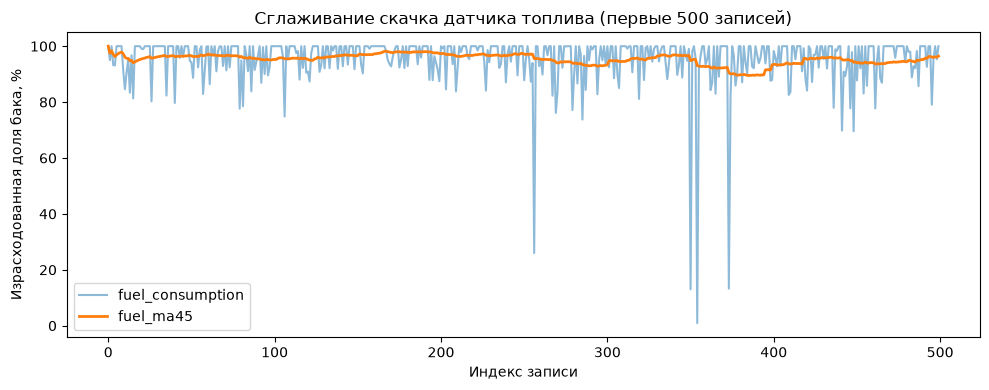

In [5]:
def moving_average_cumsum(x, k):
    x = np.asarray(x, dtype=np.float64)
    n = x.size
    cs = np.cumsum(x)
    out = np.empty(n, dtype=np.float64)
    out[:k - 1] = cs[:k - 1] / np.arange(1, k)
    out[k - 1:] = (cs[k - 1:] - np.concatenate(([0.0], cs[:-k]))) / k
    return out.astype(np.float32)

k = 45
fuel_ma = moving_average_cumsum(data_norm["fuel_consumption"], k)
speed_diff = np.diff(data_norm["speed"], prepend=data_norm["speed"][0]).astype(np.float32)

DTYPE_STAGE4 = np.dtype(DTYPE_NORM.descr + [("fuel_ma45", "<f4"), ("accel", "<f4")])
data_stage4 = np.zeros(data_norm.size, dtype=DTYPE_STAGE4)
for name in data_norm.dtype.names:
    data_stage4[name] = data_norm[name]
data_stage4["fuel_ma45"] = fuel_ma
data_stage4["accel"] = speed_diff

jump = np.diff(data_norm["fuel"], prepend=data_norm["fuel"][0])
refuel_jumps = int((jump > 20).sum())
print(f"Окно k={k}, сглаженный признак: fuel_ma45")
print(f"Резких скачков fuel > 20 п.п.: {refuel_jumps:,} ({refuel_jumps / data_norm.size:.2%})")
print(f"Диапазон accel: [{speed_diff.min():.2f}, {speed_diff.max():.2f}]")

plt.figure(figsize=(10, 4))
plt.plot(data_norm["fuel_consumption"][:500], alpha=0.5, label="fuel_consumption")
plt.plot(fuel_ma[:500], linewidth=2, label="fuel_ma45")
plt.title("Сглаживание скачка датчика топлива (первые 500 записей)")
plt.xlabel("Индекс записи")
plt.ylabel("Израсходованная доля бака, %")
plt.legend()
plt.tight_layout()
plt.show()

np.save("data_stage4.npy", data_stage4)


## 5. Производные признаки

Для variant 8 логичны два признака:

1. `speed_per_engine` — скорость на тысячу оборотов, характеристика стиля вождения;
2. `refuel_jump` — положительный скачок уровня топлива между замерами (признак заправки).

Деление выполняется через `np.where` и защищённый знаменатель `1e-8`. Возникшие `Inf`/`NaN` заменяются на 0 или медиану.


In [6]:
base = data_stage4
engine = base["engine"].astype(np.float64)
finite_engine = np.isfinite(engine)
median_engine = float(np.median(engine[finite_engine])) if finite_engine.any() else 1.0
safe_engine = np.where(finite_engine & (engine > 1e-3), engine, median_engine)

speed_per_engine = base["speed"].astype(np.float64) / np.maximum(safe_engine, 1e-3)
speed_per_engine = np.where(np.isfinite(speed_per_engine), speed_per_engine, 0.0).astype(np.float32)

refuel_jump = np.maximum(
    np.diff(base["fuel"].astype(np.float64), prepend=base["fuel"][0]),
    0.0,
).astype(np.float32)

DTYPE_FEATURES = np.dtype(DTYPE_STAGE4.descr + [
    ("speed_per_engine", "<f4"),
    ("refuel_jump", "<f4"),
])
data_features = np.zeros(base.size, dtype=DTYPE_FEATURES)
for name in base.dtype.names:
    data_features[name] = base[name]
data_features["speed_per_engine"] = speed_per_engine
data_features["refuel_jump"] = refuel_jump

print(f"speed_per_engine: mean={speed_per_engine.mean():.3f}, max={speed_per_engine.max():.3f}")
print(f"refuel_jump > 0: {int((refuel_jump > 0).sum()):,} записей")
print(f"Новых признака: 2")

np.save("data_features.npy", data_features)


speed_per_engine: mean=325.868, max=178222.375
refuel_jump > 0: 707,215 записей
Новых признака: 2


## 6. Условная агрегация по группам

Для варианта 8 логическое условие — резкий скачок уровня топлива (заправка или сброс датчика): `refuel_jump > 20` п.п. Для каждого `vehicle_id` считаем среднее, медиану и 90-й перцентиль `fuel_consumption` только на этом подмножестве. Результат — массив формы `(N_groups, 3)` со столбцами `[group_id, mean_conditional, median_conditional]` и отдельный массив p90.


In [7]:
jump_mask = data_features["refuel_jump"] > 20.0
conditional_stats = np.empty((vehicle_ids.size, 3), dtype=np.float64)
p90_conditional = np.empty(vehicle_ids.size, dtype=np.float64)

for i, vid in enumerate(vehicle_ids):
    mask = (data_features["vehicle_id"] == vid) & jump_mask
    values = data_features["fuel_consumption"][mask].astype(np.float64)
    if values.size == 0:
        conditional_stats[i] = (vid, np.nan, np.nan)
        p90_conditional[i] = np.nan
    else:
        conditional_stats[i] = (vid, values.mean(), np.median(values))
        p90_conditional[i] = np.percentile(values, 90)

conditional_rows = int(jump_mask.sum())
print(f"Записей с резким скачком топлива: {conditional_rows:,} ({conditional_rows / data_features.size:.2%})")
print(f"Форма таблицы условной статистики: {conditional_stats.shape}")
for i in range(5):
    print(f"vehicle_id={int(conditional_stats[i, 0]):3d}: mean={conditional_stats[i, 1]:.2f}, median={conditional_stats[i, 2]:.2f}, p90={p90_conditional[i]:.2f}")

np.save("data_conditional.npy", conditional_stats)


Записей с резким скачком топлива: 48,603 (2.60%)
Форма таблицы условной статистики: (100, 3)
vehicle_id=  0: mean=48.65, median=68.42, p90=79.03
vehicle_id=  1: mean=48.05, median=69.16, p90=78.83
vehicle_id=  2: mean=50.62, median=71.27, p90=79.19
vehicle_id=  3: mean=48.52, median=68.55, p90=78.92
vehicle_id=  4: mean=48.84, median=70.19, p90=78.80


## 7. Лаговые признаки и анализ временных сдвигов

Для `fuel_consumption` создаётся признак с лагом 1. Первый элемент оставляется без изменений (lag = текущее значение), чтобы не появлялся искусственный скачок на границе.

Затем считается разность, знаки разности распределяются через `np.sign` и `np.unique`.


In [8]:
d = data_features
fc = d["fuel_consumption"].astype(np.float64)
fuel_lag1 = np.roll(fc, 1)
fuel_lag1[0] = fc[0]
fuel_delta = fc - fuel_lag1

signs = np.sign(fuel_delta)
sign_values, sign_counts = np.unique(signs, return_counts=True)
sign_table = dict(zip(sign_values.astype(int).tolist(), sign_counts.tolist()))
n = d.size

rise_share = sign_table.get(1, 0) / n
fall_share = sign_table.get(-1, 0) / n
same_share = sign_table.get(0, 0) / n

print(f"Рост:   {sign_table.get(1, 0):,} ({rise_share:.2%})")
print(f"Падение:{sign_table.get(-1, 0):,} ({fall_share:.2%})")
print(f"Без изм.:{sign_table.get(0, 0):,} ({same_share:.2%})")

DTYPE_LAG = np.dtype(DTYPE_FEATURES.descr + [("fuel_lag1", "<f4"), ("fuel_delta", "<f4")])
data_lag = np.zeros(d.size, dtype=DTYPE_LAG)
for name in d.dtype.names:
    data_lag[name] = d[name]
data_lag["fuel_lag1"] = fuel_lag1.astype(np.float32)
data_lag["fuel_delta"] = fuel_delta.astype(np.float32)

np.save("data_lag.npy", data_lag)


Рост:   706,838 (37.79%)
Падение:707,214 (37.81%)
Без изм.:456,349 (24.40%)


## 8. Групповая робастная замена выбросов (IQR)

Внутри каждой группы `vehicle_id` считаются Q1, Q3 и границы `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`. Значения вне границ заменяются медианой группы. Цикл идёт по группам, а не по строкам.


In [9]:
work = data_lag.copy()
values = work["fuel_consumption"].astype(np.float64)
replaced_by_group = {}

for vid in vehicle_ids:
    mask = work["vehicle_id"] == vid
    group_values = values[mask]
    q1, q3 = np.percentile(group_values, [25, 75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = mask & ((values < lower) | (values > upper))
    replaced_by_group[int(vid)] = int(outliers.sum())
    if outliers.any():
        values[outliers] = np.median(group_values)

work["fuel_consumption"] = values.astype(np.float32)

# Пересчёт зависимых признаков после робастной замены
work["fuel_ma45"] = moving_average_cumsum(work["fuel_consumption"], k).astype(np.float32)
lag_after = np.roll(work["fuel_consumption"].astype(np.float64), 1)
lag_after[0] = work["fuel_consumption"][0]
work["fuel_lag1"] = lag_after.astype(np.float32)
work["fuel_delta"] = (work["fuel_consumption"].astype(np.float64) - lag_after).astype(np.float32)

iqr_replaced = sum(replaced_by_group.values())
iqr_share = iqr_replaced / work.size
print(f"Заменено выбросов: {iqr_replaced:,} ({iqr_share:.2%})")
print("Пример по группам:", dict(list(replaced_by_group.items())[:10]))

np.save("data_iqr.npy", work)


Заменено выбросов: 111,048 (5.94%)
Пример по группам: {0: 1027, 1: 1128, 2: 1081, 3: 1213, 4: 1083, 5: 1139, 6: 1087, 7: 1110, 8: 1164, 9: 1028}


## 9. Проверка согласованности и логической целостности

Предметные правила для GPS-телеметрии:

- `speed` должен быть в диапазоне `[0, 200]` км/ч;
- `fuel` — в `[0, 100]` %;
- `engine` — положительный и не более 8 тыс/мин;
- `acc` — статус 0 или 1.

Генератор выдаёт `acc` в диапазоне 0..499, поэтому этот флаг нормализуется через `np.where`.


In [10]:
w = work.copy()
logic_mask = (
    (w["speed"] < 0) | (w["speed"] > 200)
    | (w["fuel"] < 0) | (w["fuel"] > 100)
    | (w["engine"] <= 0) | (w["engine"] > 8)
    | ~np.isin(w["acc"], [0, 1])
)
logic_violations = int(logic_mask.sum())
logic_share = float(logic_mask.mean())

print(f"Нарушений логики: {logic_violations:,} ({logic_share:.2%})")
print(f"  acc вне {0,1}: {int((~np.isin(w['acc'], [0, 1])).sum()):,}")
print(f"  engine > 8: {int((w['engine'] > 8).sum()):,}")

w["acc"] = np.where(w["acc"] == 1, 1, 0).astype(np.uint8)
w["speed"] = np.clip(w["speed"], 0, 200).astype(np.float32)
w["fuel"] = np.clip(w["fuel"], 0, 100).astype(np.float32)
w["engine"] = np.clip(w["engine"], 0.8, 8.0).astype(np.float32)

np.save("data_consistent.npy", w)


Нарушений логики: 1,848,436 (98.83%)
  acc вне (0, 1): 1,795,986
  engine > 8: 416,770


## 10. Частотный анализ, сжатие редких категорий и итоги

Категориальное поле — `vehicle_id`. Категории с долей менее 1 % объединяются в `OTHER` с кодом `0`. Оставшиеся частые категории получают коды `1..M`, чтобы код `0` однозначно означал «редкая категория».


In [11]:
cat_ids, cat_counts = np.unique(w["vehicle_id"], return_counts=True)
threshold = 0.01 * w.size
rare_ids = cat_ids[cat_counts < threshold]
frequent_ids = cat_ids[cat_counts >= threshold]

mapping = np.zeros(int(cat_ids.max()) + 1, dtype=np.int16)
mapping[frequent_ids] = np.arange(1, frequent_ids.size + 1, dtype=np.int16)
vehicle_cat = mapping[w["vehicle_id"].astype(np.int64)].astype(np.int16)

DTYPE_FINAL = np.dtype(DTYPE_LAG.descr + [("vehicle_id_cat", "<i2")])
final = np.zeros(w.size, dtype=DTYPE_FINAL)
for name in w.dtype.names:
    final[name] = w[name]
final["vehicle_id_cat"] = vehicle_cat

print(f"Всего категорий: {cat_ids.size}")
print(f"Редких категорий (<1%): {rare_ids.size}")
print(f"Частых категорий: {frequent_ids.size}")
print(f"Код OTHER: 0; коды частых категорий: 1..{frequent_ids.size}")

np.save("data_final.npy", final)


Всего категорий: 100
Редких категорий (<1%): 49
Частых категорий: 51
Код OTHER: 0; коды частых категорий: 1..51


### Итоговые результаты и выводы

Финальный массив сохраняется в `data_final.npy`. Ниже собраны основные метрики для отчёта.


In [12]:
metrics = {
    "rows_raw": int(n_raw),
    "rows_final": int(final.size),
    "raw_nbytes": int(raw_nbytes),
    "final_nbytes": int(final.nbytes),
    "raw_mib": round(raw_nbytes / 1024**2, 2),
    "final_mib": round(final.nbytes / 1024**2, 2),
    "nan_inf_avg_share": round(total_bad_share, 4),
    "anomaly_rows": anomaly_count,
    "anomaly_share": round(anomaly_share, 4),
    "groups": int(vehicle_ids.size),
    "min_group": int(group_counts.min()),
    "max_group": int(group_counts.max()),
    "p85_engine": round(p85_engine, 3),
    "conditional_rows": conditional_rows,
    "conditional_share": round(conditional_rows / data_features.size, 4),
    "cond_mean_min": round(float(np.nanmin(conditional_stats[:, 1])), 2),
    "cond_mean_max": round(float(np.nanmax(conditional_stats[:, 1])), 2),
    "cond_p90_min": round(float(np.nanmin(p90_conditional)), 2),
    "cond_p90_max": round(float(np.nanmax(p90_conditional)), 2),
    "iqr_replaced": iqr_replaced,
    "iqr_share": round(iqr_share, 4),
    "logic_violations": logic_violations,
    "logic_share": round(logic_share, 4),
    "rare_categories": int(rare_ids.size),
    "rise_share": round(rise_share, 4),
    "fall_share": round(fall_share, 4),
    "same_share": round(same_share, 4),
    "refuel_jumps": refuel_jumps,
}

with open("metrics_lab6.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("Итоговые метрики:")
for key, value in metrics.items():
    print(f"  {key:22s}: {value}")

print("\nФинальный массив сохранён: data_final.npy")
print("Все этапы выполнены без циклов по строкам исходного массива.")


Итоговые метрики:
  rows_raw              : 2000000
  rows_final            : 1870401
  raw_nbytes            : 38000000
  final_nbytes          : 99131253
  raw_mib               : 36.24
  final_mib             : 94.54
  nan_inf_avg_share     : 0.03
  anomaly_rows          : 129599
  anomaly_share         : 0.0648
  groups                : 100
  min_group             : 18411
  max_group             : 19029
  p85_engine            : 11.17
  conditional_rows      : 48603
  conditional_share     : 0.026
  cond_mean_min         : 44.77
  cond_mean_max         : 51.99
  cond_p90_min          : 78.4
  cond_p90_max          : 79.24
  iqr_replaced          : 111048
  iqr_share             : 0.0594
  logic_violations      : 1848436
  logic_share           : 0.9883
  rare_categories       : 49
  rise_share            : 0.3779
  fall_share            : 0.3781
  same_share            : 0.244
  refuel_jumps          : 48603

Финальный массив сохранён: data_final.npy
Все этапы выполнены без циклов 